# Milestone 2 - Mesurer la situation actuelle

**But :** décrire précisément comment les fournisseurs livrent les usines aujourd'hui, chiffrer ce que cela coûte et identifier les couples où la consolidation rapportera le plus.
La situation actuelle est la **référence (baseline)** à laquelle le moteur du Milestone 3 sera comparé (EF04).

**Entrée :** `data/consolidated_dataset.csv`, produit par `milestone1/preparation.ipynb` (besoins nettoyés, sans le cumul du 01/01 ni les lignes plus lourdes qu'un camion).
La colonne `rate_cost` n'est pas utilisée : le prix dépend du poids de l'**envoi complet**, pas de celui d'une ligne. Il est recalculé ici, livraison par livraison.

| Étape | Question | Règle / exigence |
| :--- | :--- | :--- |
| **1** | Données d'entrée et grille tarifaire | EF01 |
| **2** | Comment passe-t-on des lignes de besoin aux livraisons ? | RG01, RG12 |
| **3** | Combien de livraisons par couple, par usine et par semaine ? | EF04 |
| **4** | Quels poids, volume et remplissage par livraison ? | RG04 |
| **5** | Combien coûte une livraison ? (estimateur de coût) | RG11 |
| **6** | Quels indicateurs de référence ? | EF04, EF08 |
| **7** | Quels couples ont le plus de potentiel ? | EF04 |
| **8** | Export des résultats de référence | EF04 |

## Paramètres communs

In [1]:
from __future__ import annotations

import logging
import re
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from pypdf import PdfReader

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)-7s %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
logging.getLogger("pypdf").setLevel(logging.ERROR)
logging.getLogger("matplotlib").setLevel(logging.WARNING)
logger = logging.getLogger("baseline")


@dataclass(frozen=True)
class BaselineConfig:
    """All tunable parameters of the baseline measurement (EF12)."""

    data_dir: Path = Path("../data")
    docs_dir: Path = Path("../docs")
    output_dir: Path = Path("../data")
    truck_kg: float = 24_500.0  # RG04: weight capacity of one truck
    truck_m3: float = 110.4  # RG04: volume capacity of one truck
    margin: float = 2.3923  # RG11 / EF12: freight value margin (239.23 %), as printed in rate_sheet.pdf
    diesel_surcharge: float = 1.1943  # RG11 / EF12: diesel surcharge factor, as printed in rate_sheet.pdf
    couple_key: tuple[str, ...] = ("supplier_id", "plant")  # RG01
    pareto_share_a: float = 0.80  # class A = couples carrying the first 80 % of the potential saving
    pareto_share_b: float = 0.95  # class B = up to 95 %, class C = the rest


cfg = BaselineConfig()

# Chart style: thin marks, light grid, one colour per plant (fixed order)
PLANT_COLORS = {"PLT_001": "#2a78d6", "PLT_002": "#eb6834", "PLT_003": "#1baf7a", "PLT_004": "#eda100"}
PRIMARY, MUTED, ACCENT = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e4e3df",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

## 1. Données d'entrée

Le dataset consolidé contient une ligne par besoin (fournisseur × material × usine × quai × jour), avec sa distance.
La grille tarifaire vient de `data/rate_sheet_long.csv`. La marge et la surcharge diesel sont des paramètres communs (`BaselineConfig`, EF12), comme dans `milestone1.ipynb` ; on vérifie qu'ils correspondent toujours au PDF.

In [2]:
needs = pd.read_csv(cfg.data_dir / "consolidated_dataset.csv", parse_dates=["date"])
needs = needs.drop(columns="rate_cost", errors="ignore")  # price of a single line: not a transport cost
rate_sheet_long = pd.read_csv(cfg.data_dir / "rate_sheet_long.csv")


def read_price_factors(pdf_path: Path) -> tuple[float, float]:
    """Margin and diesel surcharge printed under the grid of the rate sheet PDF."""
    text = "\n".join(page.extract_text() or "" for page in PdfReader(pdf_path).pages)
    margin = re.search(r"margin:\s*([\d.,]+)\s*%", text)
    diesel = re.search(r"Diesel surcharge:\s*([\d.,]+)", text)
    if margin is None or diesel is None:
        raise ValueError("Rate sheet: margin or diesel surcharge not found")
    return float(margin.group(1).replace(",", ".")) / 100, float(diesel.group(1).replace(",", "."))


# EF12: margin and diesel come from the common parameters; warn if the PDF says otherwise
pdf_margin, pdf_diesel = read_price_factors(cfg.docs_dir / "rate_sheet.pdf")
if not (np.isclose(pdf_margin, cfg.margin) and np.isclose(pdf_diesel, cfg.diesel_surcharge)):
    logger.warning("Configured margin / diesel (%.4f / %.4f) differ from rate_sheet.pdf (%.4f / %.4f): "
                   "the configuration is used", cfg.margin, cfg.diesel_surcharge, pdf_margin, pdf_diesel)
MARGIN, DIESEL = cfg.margin, cfg.diesel_surcharge
PRICE_FACTOR = (1 + MARGIN) * DIESEL

assert needs[["weight", "volume", "distance"]].notna().all().all(), "missing load or distance"
assert (needs["weight"] <= cfg.truck_kg).all(), "a single line heavier than a truck (removed by DQ07)"
logger.info("Needs: %d rows, %d couples, %s -> %s", len(needs), needs.groupby(list(cfg.couple_key)).ngroups,
            needs["date"].min().date(), needs["date"].max().date())
logger.info("Rate sheet: %d cells | margin %.2f %% | diesel x%.4f | price factor x%.4f",
            len(rate_sheet_long), MARGIN * 100, DIESEL, PRICE_FACTOR)
needs.head()

14:43:40 INFO    Needs: 4389 rows, 180 couples, 2026-11-09 -> 2026-12-18


14:43:40 INFO    Rate sheet: 210 cells | margin 239.23 % | diesel x1.1943 | price factor x4.0514


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,distance
0,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
1,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
2,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
3,2026-11-18,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
4,2026-11-19,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00


## 2. Des lignes de besoin aux livraisons

**Définition (RG12) :** aujourd'hui, chaque fournisseur livre une usine le jour même de chaque besoin.
Une **livraison** est donc un **couple fournisseur × usine × jour** : toutes les lignes de ce jour (plusieurs *materials*, éventuellement plusieurs quais) partent dans le même envoi.
C'est aussi l'unité facturée par le transporteur : le poids qui fixe le prix est celui de l'envoi complet.

Le remplissage d'un camion est le plus élevé des deux ratios poids / 24,5 t et volume / 110,4 m³ (RG04) ; au-delà de 100 %, il faut un camion de plus.
Aucun jour férié allemand ne tombe dans l'horizon (09/11 → 18/12) : chaque jour de besoin est un jour de livraison.

In [3]:
DAYS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]


def build_deliveries(lines: pd.DataFrame) -> pd.DataFrame:
    """One row per couple x day: the load that leaves together today (RG12)."""
    deliveries = (
        lines.groupby([*cfg.couple_key, "date"])
        .agg(
            lines=("material", "size"),
            materials=("material", "nunique"),
            unloading_points=("unloading_point", "nunique"),
            weight=("weight", "sum"),
            volume=("volume", "sum"),
            distance=("distance", "first"),
        )
        .reset_index()
    )
    deliveries["week"] = deliveries["date"] - pd.to_timedelta(deliveries["date"].dt.day_of_week, unit="D")
    deliveries["weekday"] = deliveries["date"].dt.day_of_week.map(dict(enumerate(DAYS)))  # day name (lundi ... vendredi)
    deliveries["fill_weight"] = deliveries["weight"] / cfg.truck_kg
    deliveries["fill_volume"] = deliveries["volume"] / cfg.truck_m3
    deliveries["fill"] = deliveries[["fill_weight", "fill_volume"]].max(axis=1)
    deliveries["trucks"] = np.ceil(deliveries["fill"]).astype(int)
    deliveries["binding"] = np.where(deliveries["fill_weight"] >= deliveries["fill_volume"], "weight", "volume")
    return deliveries


deliveries = build_deliveries(needs)
N_WEEKS = deliveries["week"].nunique()

assert np.isclose(deliveries["weight"].sum(), needs["weight"].sum()), "weight lost in the aggregation"
assert deliveries["lines"].sum() == len(needs), "line lost in the aggregation"
logger.info("%d lines -> %d deliveries (couple x day) over %d weeks", len(needs), len(deliveries), N_WEEKS)
deliveries.head()

14:43:40 INFO    4389 lines -> 1665 deliveries (couple x day) over 6 weeks


,supplier_id,plant,date,lines,materials,unloading_points,weight,volume,distance,week,weekday,fill_weight,fill_volume,fill,trucks,binding
0,SUP_00001,PLT_004,2026-11-26,4,4,1,689.30,3.39,47.00,2026-11-23,jeudi,0.03,0.03,0.03,1,volume
1,SUP_00001,PLT_004,2026-11-27,1,1,1,169.10,0.42,47.00,2026-11-23,vendredi,0.01,0.00,0.01,1,weight
2,SUP_00001,PLT_004,2026-11-30,1,1,1,169.10,0.42,47.00,2026-11-30,lundi,0.01,0.00,0.01,1,weight
3,SUP_00001,PLT_004,2026-12-01,1,1,1,169.10,0.42,47.00,2026-11-30,mardi,0.01,0.00,0.01,1,weight
4,SUP_00001,PLT_004,2026-12-02,1,1,1,169.10,0.42,47.00,2026-11-30,mercredi,0.01,0.00,0.01,1,weight


## 3. Livraisons par couple, par usine et par semaine

### 3.1 Par couple : fréquence actuelle

La fréquence d'un couple est son nombre de livraisons divisé par ses **semaines actives** (semaines avec au moins un besoin).
Diviser par les 6 semaines de l'horizon sous-estimerait le rythme des couples qui ne livrent que certaines semaines.

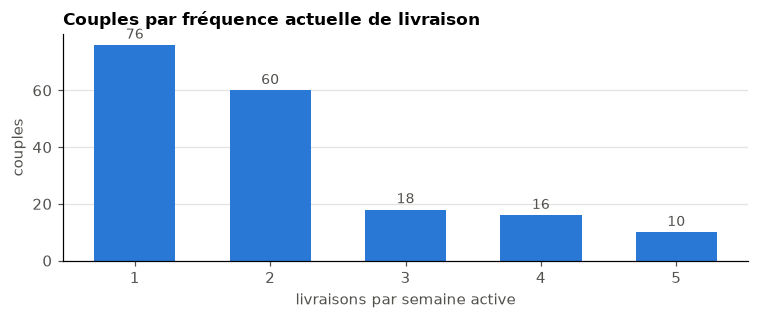

Semaines actives : {1: 20, 2: 24, 3: 25, 4: 24, 5: 30, 6: 57} (semaines -> couples)
Couples avec une seule livraison sur l'horizon : 18


,couples,livraisons,% des livraisons
livraisons / semaine,,,
1,76,265,15.92
2,60,452,27.15
3,18,299,17.96
4,16,358,21.50
5,10,291,17.48


In [4]:
couples = (
    deliveries.groupby(list(cfg.couple_key))
    .agg(deliveries=("date", "size"), active_weeks=("week", "nunique"), distance=("distance", "first"))
    .reset_index()
)
couples["per_week"] = couples["deliveries"] / couples["active_weeks"]
couples["frequency"] = couples["per_week"].round().astype(int)

freq = couples["frequency"].value_counts().sort_index().rename("couples").to_frame()
freq["livraisons"] = couples.groupby("frequency")["deliveries"].sum()
freq["% des livraisons"] = 100 * freq["livraisons"] / freq["livraisons"].sum()
freq.index.name = "livraisons / semaine"

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(freq.index.astype(str), freq["couples"], color=PRIMARY, width=0.6)
ax.bar_label(bars, padding=2, fontsize=9, color=MUTED)
ax.set_title("Couples par fréquence actuelle de livraison")
ax.set_xlabel("livraisons par semaine active"); ax.set_ylabel("couples")
plt.tight_layout(); plt.show()

print(f"Semaines actives : {couples['active_weeks'].value_counts().sort_index().to_dict()} (semaines -> couples)")
print(f"Couples avec une seule livraison sur l'horizon : {(couples['deliveries'] == 1).sum()}")
freq

### 3.2 Par usine et par semaine

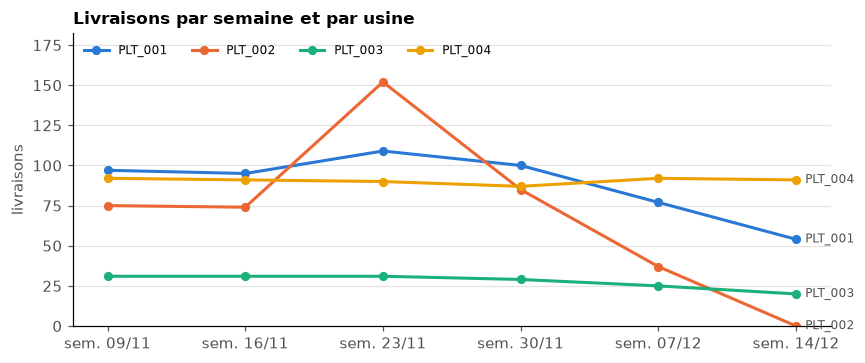

,09/11,16/11,23/11,30/11,07/12,14/12,total
plant,,,,,,,
PLT_001,97,95,109,100,77,54,532
PLT_002,75,74,152,85,37,0,423
PLT_003,31,31,31,29,25,20,167
PLT_004,92,91,90,87,92,91,543
total,295,291,382,301,231,165,1665


In [5]:
plant_week = pd.crosstab(deliveries["plant"], deliveries["week"], margins=True, margins_name="total")
plant_week.columns = [c.strftime("%d/%m") if isinstance(c, pd.Timestamp) else c for c in plant_week.columns]

weekly = deliveries.groupby(["week", "plant"]).size().unstack("plant", fill_value=0)  # a week without delivery counts as 0
fig, ax = plt.subplots(figsize=(8, 3.4))
for plant in weekly.columns:
    ax.plot(weekly.index, weekly[plant], marker="o", markersize=5, lw=2, color=PLANT_COLORS[plant], label=plant)
    ax.annotate(plant, (weekly.index[-1], weekly[plant].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=MUTED)
ax.set_xticks(weekly.index, [d.strftime("sem. %d/%m") for d in weekly.index])
ax.set_title("Livraisons par semaine et par usine")
ax.set_ylabel("livraisons"); ax.legend(ncols=4, loc="upper left", fontsize=8)
ax.set_ylim(0, weekly.max().max() * 1.2)
plt.tight_layout(); plt.show()
plant_week

### 3.3 Par jour de la semaine (point de départ du lissage)

In [6]:
days = [d for d in DAYS if d in set(deliveries["weekday"])]  # working days, in calendar order
plant_day = pd.crosstab(deliveries["plant"], deliveries["weekday"], margins=True, margins_name="total")
plant_day = plant_day[[*days, "total"]]
share = plant_day[days].div(plant_day[days].sum(axis=1), axis=0).mul(100).round(1)
share.columns = [f"% {d}" for d in days]
plant_day.join(share)

,lundi,mardi,mercredi,jeudi,vendredi,total,% lundi,% mardi,% mercredi,% jeudi,% vendredi
plant,,,,,,,,,,,
PLT_001,89,108,112,117,106,532,16.70,20.30,21.10,22.00,19.90
PLT_002,91,69,49,97,117,423,21.50,16.30,11.60,22.90,27.70
PLT_003,20,56,19,60,12,167,12.00,33.50,11.40,35.90,7.20
PLT_004,107,97,114,103,122,543,19.70,17.90,21.00,19.00,22.50
total,307,330,294,377,357,1665,18.40,19.80,17.70,22.60,21.40


**Lecture :**
- 136 couples sur 180 sont déjà livrés 1 ou 2 fois par semaine. Mais les **44 couples livrés 3 à 5 fois portent 57 % des livraisons** : c'est là que la consolidation réduira le plus le nombre d'envois.
- PLT_004 et PLT_001 reçoivent le plus de livraisons. PLT_002 a un pic la semaine du 23/11 puis plus aucun besoin à partir du 10/12.
- PLT_003 concentre 69 % de ses livraisons le mardi et le jeudi ; les autres usines sont déjà assez équilibrées sur la semaine.
- Les deux dernières semaines sont plus creuses : les besoins s'arrêtent le 18/12. Ce sont des données réelles, pas des trous à compléter.

## 4. Poids, volume et remplissage par livraison

In [7]:
load_cols = ["weight", "volume", "fill_weight", "fill_volume", "fill"]
dist = deliveries[load_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
dist.index = ["poids (kg)", "volume (m³)", "remplissage poids", "remplissage volume", "remplissage (max)"]
dist

,count,mean,std,min,25%,50%,75%,90%,99%,max
poids (kg),1 665.00,986.55,2 759.74,0.77,129.00,327.00,798.00,1 960.43,15 627.55,46 733.64
volume (m³),1 665.00,1.74,2.75,0.01,0.42,1.20,1.93,3.77,9.57,39.01
remplissage poids,1 665.00,0.04,0.11,0.00,0.01,0.01,0.03,0.08,0.64,1.91
remplissage volume,1 665.00,0.02,0.02,0.00,0.00,0.01,0.02,0.03,0.09,0.35
remplissage (max),1 665.00,0.04,0.11,0.00,0.01,0.01,0.03,0.08,0.64,1.91


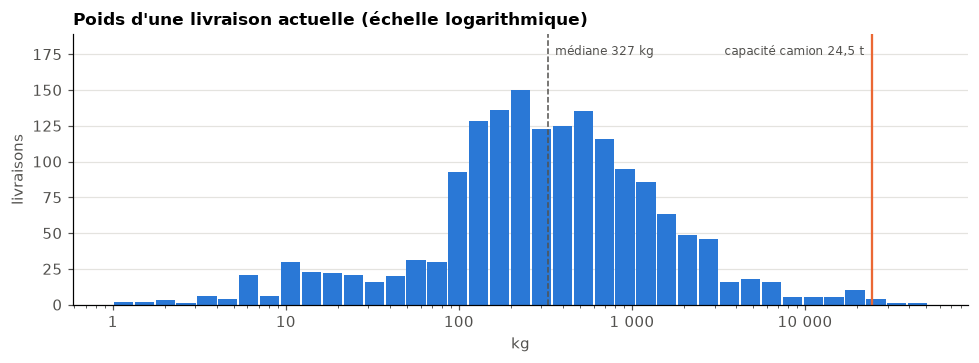

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.logspace(0, np.log10(deliveries["weight"].max() * 1.1), 40)
ax.hist(deliveries["weight"], bins=bins, color=PRIMARY, rwidth=0.92)
ax.set_xscale("log")
y_top = ax.get_ylim()[1] * 1.2
ax.set_ylim(0, y_top)
median_w = deliveries["weight"].median()
ax.axvline(cfg.truck_kg, color=ACCENT, lw=1.5)
ax.text(cfg.truck_kg * 0.9, y_top * 0.96, "capacité camion 24,5 t", ha="right", va="top", fontsize=8, color=MUTED)
ax.axvline(median_w, color=MUTED, lw=1, ls="--")
ax.text(median_w * 1.1, y_top * 0.96, f"médiane {median_w:.0f} kg", va="top", fontsize=8, color=MUTED)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set_title("Poids d'une livraison actuelle (échelle logarithmique)")
ax.set_xlabel("kg"); ax.set_ylabel("livraisons")
plt.tight_layout(); plt.show()

In [9]:
by_plant = deliveries.groupby("plant").agg(
    livraisons=("date", "size"),
    poids_median_kg=("weight", "median"),
    volume_median_m3=("volume", "median"),
    remplissage_median=("fill", "median"),
    remplissage_p90=("fill", lambda s: s.quantile(0.9)),
    part_volume_limitant=("binding", lambda s: (s == "volume").mean()),
)
by_plant["remplissage_median"] *= 100
by_plant["remplissage_p90"] *= 100
by_plant["part_volume_limitant"] *= 100

print(f"Contrainte limitante : poids {(deliveries['binding'] == 'weight').mean():.0%} | "
      f"volume {(deliveries['binding'] == 'volume').mean():.0%}")
print(f"Livraisons de plus d'un camion : {(deliveries['trucks'] > 1).sum()} "
      f"| livraisons ≤ 1 000 kg : {(deliveries['weight'] <= 1000).mean():.0%}")
by_plant.rename(columns={"remplissage_median": "remplissage médian (%)", "remplissage_p90": "remplissage P90 (%)",
                         "part_volume_limitant": "volume limitant (%)"})

Contrainte limitante : poids 69% | volume 31%
Livraisons de plus d'un camion : 4 | livraisons ≤ 1 000 kg : 80%


,livraisons,poids_median_kg,volume_median_m3,remplissage médian (%),remplissage P90 (%),volume limitant (%)
plant,,,,,,
PLT_001,532,243.30,0.57,1.00,5.63,13.72
PLT_002,423,263.80,1.20,1.22,9.82,42.08
PLT_003,167,595.74,1.20,2.43,11.30,8.98
PLT_004,543,398.10,1.30,1.94,7.87,46.41


**Lecture :** une livraison typique pèse environ 330 kg et remplit 1 à 2 % d'un camion ; 90 % des livraisons remplissent moins de 8 % d'un camion, et 80 % pèsent 1 000 kg ou moins.
Le poids est la contrainte limitante dans environ deux livraisons sur trois, le volume dans le tiers restant : les deux limites doivent être suivies par le moteur.

## 5. Estimateur de coût (RG11)

**Règle :** le prix d'un envoi se lit dans la grille avec la **distance du fournisseur** (ligne) et le **poids total de l'envoi** (colonne), puis :

`prix = coût de base × (1 + marge) × surcharge diesel`

- Les bornes de la grille sont des maxima inclusifs (« up to ») : 121 km se lit sur la ligne ≤ 125 km.
- Au-delà de 4 000 kg, le tarif est forfaitaire (colonne `> 4000`).
- **Hypothèse :** une livraison qui dépasse un camion est répartie à parts égales sur `n` camions, chacun facturé comme un envoi.

In [10]:
KM_BOUNDS = np.sort(rate_sheet_long["km_max"].unique())
KG_BOUNDS = np.sort(rate_sheet_long["kg_max"].unique())
GRID = rate_sheet_long.pivot(index="km_max", columns="kg_max", values="base_cost")


def bracket(values, bounds: np.ndarray) -> np.ndarray:
    """Smallest bound >= value: the bounds of the rate sheet are inclusive maxima."""
    position = np.searchsorted(bounds, np.asarray(values, dtype=float), side="left")
    if (position >= len(bounds)).any():
        raise ValueError("value outside the rate sheet")
    return bounds[position]


def shipment_cost(distance_km, weight_kg, trucks=1) -> np.ndarray:
    """Transport price in EUR of one shipment (vectorised): grid x (1 + margin) x diesel, per truck."""
    trucks = np.maximum(np.asarray(trucks), 1)
    weight_per_truck = np.asarray(weight_kg, dtype=float) / trucks
    km = bracket(distance_km, KM_BOUNDS)
    kg = bracket(weight_per_truck, KG_BOUNDS)
    base = GRID.to_numpy()[np.searchsorted(GRID.index, km), np.searchsorted(GRID.columns, kg)]
    return base * PRICE_FACTOR * trucks


deliveries["cost"] = shipment_cost(deliveries["distance"], deliveries["weight"], deliveries["trucks"])
logger.info("Baseline cost: %.0f EUR for %d deliveries", deliveries["cost"].sum(), len(deliveries))

14:43:41 INFO    Baseline cost: 149411 EUR for 1665 deliveries


### Validation de l'estimateur

On retrouve les deux exemples des documents du projet :
1. l'exemple de la *rate sheet* : 300 km, 1 000 kg → 335,34 € ;
2. l'exemple du cahier des charges : SUP_00085 → PLT_004, semaine du 16/11 : 5 envois aujourd'hui (≈ 1 215 €) contre 1 seul envoi groupé le lundi (≈ 331 €).

In [11]:
assert np.isclose(shipment_cost(300, 1_000), 335.34, atol=0.01)
assert np.isclose(shipment_cost(30, 50), shipment_cost(30, 50.0)) and shipment_cost(31, 51) > shipment_cost(30, 50)  # bounds are inclusive

example = deliveries[(deliveries["supplier_id"] == "SUP_00085") & (deliveries["plant"] == "PLT_004")
                     & deliveries["date"].between("2026-11-16", "2026-11-20")]
grouped_cost = shipment_cost(example["distance"].iloc[0], example["weight"].sum())[()]
validation = pd.DataFrame({
    "cas": ["Rate sheet : 300 km, 1 000 kg", "SUP_00085, semaine du 16/11 : 5 envois (aujourd'hui)",
            "SUP_00085, semaine du 16/11 : 1 envoi groupé"],
    "attendu (EUR)": [335.34, 1215, 331],
    "calculé (EUR)": [shipment_cost(300, 1_000)[()], example["cost"].sum(), grouped_cost],
})
validation["écart (EUR)"] = (validation["calculé (EUR)"] - validation["attendu (EUR)"]).abs()
assert (validation["écart (EUR)"] < 1).all(), "the estimator does not reproduce the documented examples"
validation

,cas,attendu (EUR),calculé (EUR),écart (EUR)
0,"Rate sheet : 300 km, 1 000 kg",335.34,335.34,0.00
1,"SUP_00085, semaine du 16/11 : 5 envois (aujour...",1 215.00,1 215.47,0.47
2,"SUP_00085, semaine du 16/11 : 1 envoi groupé",331.00,331.41,0.41


## 6. Indicateurs de référence (baseline)

Ce sont les valeurs à battre au Milestone 3. Le coût est recalculé envoi par envoi avec l'estimateur ci-dessus.

In [12]:
def kpis(d: pd.DataFrame) -> pd.Series:
    """Baseline indicators of a set of deliveries."""
    return pd.Series({
        "couples": d.groupby(list(cfg.couple_key)).ngroups,
        "livraisons": len(d),
        "camions": int(d["trucks"].sum()),
        "livraisons / semaine": len(d) / N_WEEKS,
        "poids total (t)": d["weight"].sum() / 1000,
        "poids médian d'une livraison (kg)": d["weight"].median(),
        "remplissage médian (%)": 100 * d["fill"].median(),
        "remplissage moyen pondéré (%)": 100 * d["weight"].sum() / (d["trucks"].sum() * cfg.truck_kg),
        "coût total (EUR)": d["cost"].sum(),
        "coût / semaine (EUR)": d["cost"].sum() / N_WEEKS,
        "coût moyen d'une livraison (EUR)": d["cost"].mean(),
        "coût au kg (EUR/kg)": d["cost"].sum() / d["weight"].sum(),
    })


baseline_kpis = pd.concat({"total": kpis(deliveries), **{p: kpis(g) for p, g in deliveries.groupby("plant")}}, axis=1)
baseline_kpis

,total,PLT_001,PLT_002,PLT_003,PLT_004
couples,180.00,51.00,64.00,26.00,39.00
livraisons,1 665.00,532.00,423.00,167.00,543.00
camions,1 669.00,532.00,424.00,167.00,546.00
livraisons / semaine,277.50,88.67,70.50,27.83,90.50
poids total (t),1 642.60,347.29,397.27,203.10,694.94
poids médian d'une livraison (kg),327.00,243.30,263.80,595.74,398.10
remplissage médian (%),1.45,1.00,1.22,2.43,1.94
remplissage moyen pondéré (%),4.02,2.66,3.82,4.96,5.20
coût total (EUR),149 410.56,40 708.50,35 470.22,20 628.39,52 603.44
coût / semaine (EUR),24 901.76,6 784.75,5 911.70,3 438.07,8 767.24


In [13]:
cost_week = deliveries.pivot_table(index="plant", columns="week", values="cost", aggfunc="sum", fill_value=0)
cost_week.columns = [c.strftime("%d/%m") for c in cost_week.columns]
cost_week.loc["total"] = cost_week.sum()
cost_week.round(0)

,09/11,16/11,23/11,30/11,07/12,14/12
plant,,,,,,
PLT_001,7 261.00,7 410.00,7 894.00,8 057.00,6 221.00,3 866.00
PLT_002,6 605.00,5 483.00,13 780.00,6 416.00,3 187.00,0.00
PLT_003,3 733.00,4 024.00,3 840.00,3 584.00,2 988.00,2 459.00
PLT_004,9 261.00,8 934.00,8 873.00,8 721.00,8 254.00,8 559.00
total,26 860.00,25 852.00,34 387.00,26 778.00,20 650.00,14 884.00


**Lecture :** le coût au kilo est élevé parce que la grande majorité des envois sont légers, là où le tarif au kilo est le plus cher (la grille est très dégressive avec le poids, puis forfaitaire au-delà de 4 t).
Faire baisser le **nombre d'envois** est donc le levier principal.

## 7. Classement des couples selon leur potentiel

**Méthode :** pour mesurer le potentiel de chaque couple, on chiffre un scénario simple : **une seule livraison par semaine**, qui regroupe tous les besoins de la semaine.
C'est la fréquence la plus basse autorisée (RG05). Elle donne une **borne indicative** du saving, pas la solution : le Milestone 3 ajoutera les jours fixes, le lissage et la préférence du client pour ajouter des jours de livraison plutôt que des camions.

Le potentiel d'un couple = coût actuel − coût du scénario. Les couples sont ensuite classés en **A / B / C** selon leur part cumulée du saving (A : 80 % du potentiel, B : jusqu'à 95 %, C : le reste).

In [14]:
weekly_load = (
    deliveries.groupby([*cfg.couple_key, "week"])
    .agg(weight=("weight", "sum"), volume=("volume", "sum"), distance=("distance", "first"))
    .reset_index()
)
weekly_load["trucks"] = np.ceil(np.maximum(weekly_load["weight"] / cfg.truck_kg, weekly_load["volume"] / cfg.truck_m3)).astype(int)
weekly_load["cost"] = shipment_cost(weekly_load["distance"], weekly_load["weight"], weekly_load["trucks"])

current = deliveries.groupby(list(cfg.couple_key)).agg(current_cost=("cost", "sum"), weight=("weight", "sum"),
                                                        median_fill=("fill", "median"))
scenario = weekly_load.groupby(list(cfg.couple_key)).agg(weekly_cost=("cost", "sum"), weekly_deliveries=("week", "size"),
                                                         weekly_trucks=("trucks", "sum"))
ranking = couples.set_index(list(cfg.couple_key)).join(current).join(scenario)
ranking["saving"] = ranking["current_cost"] - ranking["weekly_cost"]
ranking["saving_pct"] = 100 * ranking["saving"] / ranking["current_cost"]
ranking = ranking.sort_values("saving", ascending=False)
ranking["rank"] = np.arange(1, len(ranking) + 1)
ranking["cum_share"] = ranking["saving"].cumsum() / ranking["saving"].sum()
ranking["potential_class"] = np.select(
    [ranking["cum_share"].shift(fill_value=0) < cfg.pareto_share_a,
     ranking["cum_share"].shift(fill_value=0) < cfg.pareto_share_b], ["A", "B"], "C")
ranking = ranking.reset_index()

assert (ranking["saving"] >= -0.01).all(), "grouping a week should never cost more than delivering daily"
summary = ranking.groupby("potential_class").agg(couples=("rank", "size"), saving_eur=("saving", "sum"),
                                                 current_cost_eur=("current_cost", "sum"))
summary["% du saving"] = 100 * summary["saving_eur"] / summary["saving_eur"].sum()
logger.info("Weekly scenario: %.0f EUR -> %.0f EUR (-%.0f %%)", ranking["current_cost"].sum(),
            ranking["weekly_cost"].sum(), 100 * ranking["saving"].sum() / ranking["current_cost"].sum())
summary

14:43:41 INFO    Weekly scenario: 149411 EUR -> 90969 EUR (-39 %)


,couples,saving_eur,current_cost_eur,% du saving
potential_class,,,,
A,41,46 997.29,93 713.85,80.42
B,34,8 620.46,28 420.62,14.75
C,105,2 823.80,27 276.09,4.83


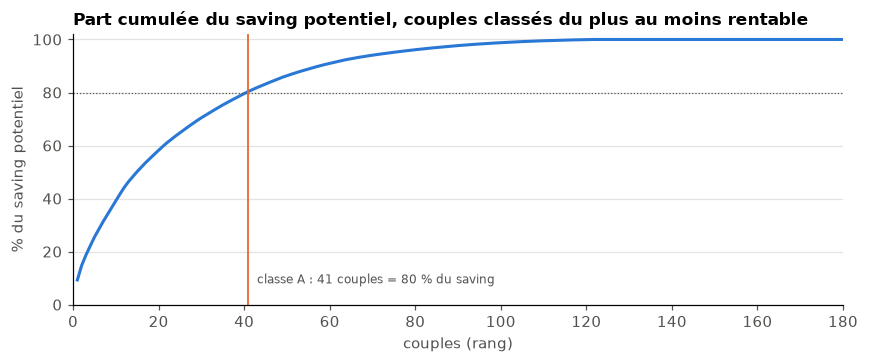

,rank,supplier_id,plant,distance,livraisons / sem.,deliveries,remplissage médian (%),coût actuel (EUR),coût 1 / semaine (EUR),saving (EUR),saving (%),classe
0,1,SUP_00085,PLT_004,121.00,5,30,9.92,7 429.18,1 988.44,5 440.74,73.23,A
1,2,SUP_00146,PLT_002,122.00,4,20,10.46,4 651.48,1 472.49,3 178.99,68.34,A
2,3,SUP_00129,PLT_003,84.00,4,27,4.38,3 963.75,1 671.21,2 292.54,57.84,A
3,4,SUP_00059,PLT_003,122.00,4,25,2.43,3 874.58,1 859.00,2 015.58,52.02,A
4,5,SUP_00144,PLT_001,38.00,3,20,10.96,3 240.69,1 283.49,1 957.20,60.39,A
5,6,SUP_00080,PLT_004,40.00,5,29,4.35,2 989.46,1 276.40,1 713.06,57.30,A
6,7,SUP_00118,PLT_001,100.00,5,29,2.11,3 210.51,1 540.68,1 669.83,52.01,A
7,8,SUP_00149,PLT_004,13.00,5,30,3.17,2 516.99,963.75,1 553.23,61.71,A
8,9,SUP_00087,PLT_004,98.00,5,28,2.98,2 995.95,1 446.40,1 549.55,51.72,A
9,10,SUP_00011,PLT_004,145.00,5,30,1.32,2 861.52,1 320.68,1 540.84,53.85,A


In [15]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ranking["rank"], 100 * ranking["cum_share"], color=PRIMARY, lw=2)
n_a = (ranking["potential_class"] == "A").sum()
ax.axhline(100 * cfg.pareto_share_a, color=MUTED, lw=0.8, ls=":")
ax.axvline(n_a, color=ACCENT, lw=1.2)
ax.text(n_a + 2, 8, f"classe A : {n_a} couples = {100 * cfg.pareto_share_a:.0f} % du saving", fontsize=8, color=MUTED)
ax.set_xlim(0, len(ranking)); ax.set_ylim(0, 102)
ax.set_title("Part cumulée du saving potentiel, couples classés du plus au moins rentable")
ax.set_xlabel("couples (rang)"); ax.set_ylabel("% du saving potentiel")
plt.tight_layout(); plt.show()

cols = ["rank", "supplier_id", "plant", "distance", "frequency", "deliveries", "median_fill",
        "current_cost", "weekly_cost", "saving", "saving_pct", "potential_class"]
top = ranking[cols].head(15).copy()
top["median_fill"] *= 100
top.rename(columns={"frequency": "livraisons / sem.", "median_fill": "remplissage médian (%)",
                    "current_cost": "coût actuel (EUR)", "weekly_cost": "coût 1 / semaine (EUR)",
                    "saving": "saving (EUR)", "saving_pct": "saving (%)", "potential_class": "classe"})

**Lecture :** le potentiel est très concentré. **41 couples (classe A) portent 80 % du saving potentiel** ; ils sont tous livrés au moins 2 fois par semaine, et 34 d'entre eux 3 à 5 fois. Ce sont eux que le moteur du Milestone 3 doit traiter en priorité.
Les 105 couples de classe C sont déjà livrés 1 fois (75 couples) ou 2 fois (30 couples) par semaine : ils ne représentent que 5 % du saving.

## 8. Résultat et export

| Fichier | Une ligne = | Usage |
| :--- | :--- | :--- |
| `baseline_deliveries.csv` | une livraison actuelle (couple × jour), avec charge, remplissage et coût | référence détaillée pour le Milestone 3 |
| `baseline_couples.csv` | un couple, avec fréquence, coût actuel, potentiel et classe A / B / C | classement des couples |
| `baseline_kpis.csv` | un indicateur, au total et par usine | indicateurs de référence |

In [16]:
cfg.output_dir.mkdir(parents=True, exist_ok=True)
deliveries.to_csv(cfg.output_dir / "baseline_deliveries.csv", index=False, date_format="%Y-%m-%d")
ranking.to_csv(cfg.output_dir / "baseline_couples.csv", index=False)
baseline_kpis.to_csv(cfg.output_dir / "baseline_kpis.csv", index_label="indicator")
logger.info("Files written to %s", cfg.output_dir.resolve().name)

pd.DataFrame({
    "fichier": ["baseline_deliveries.csv", "baseline_couples.csv", "baseline_kpis.csv"],
    "lignes": [len(deliveries), len(ranking), len(baseline_kpis)],
}).set_index("fichier")

14:43:42 INFO    Files written to data


,lignes
fichier,
baseline_deliveries.csv,1665
baseline_couples.csv,180
baseline_kpis.csv,12


## Synthèse

- **Situation actuelle :** 1 665 livraisons en 6 semaines pour 180 couples, chacune le jour même du besoin ; poids médian 327 kg, remplissage médian 1,5 %.
- **Coût de référence : 149 411 € sur 6 semaines (≈ 24 900 € par semaine)**, recalculé envoi par envoi avec un estimateur validé sur les deux exemples des documents du projet.
- **Potentiel :** livrer une fois par semaine ramènerait le coût à environ 91 000 € (**−39 %**, borne indicative). 41 couples (classe A) portent 80 % de ce gain.
- **Pour le Milestone 3 :** réutiliser `shipment_cost` pour chiffrer chaque solution, et commencer par les couples de classe A.